# Scene 3 Expected SARSA Evaluation, and Report Evidence
## 1. Environment Design and Architecture

The environment acts as the physical simulation where the agent operates. It is built in the Godot Engine and handles game physics, collision detection, and entity management.

### Scene Layout & Objectives
The scene is a 2D platformer requiring the agent to navigate vertical and horizontal obstacles. The primary objective is to collect two apples while avoiding patrolling snail enemies. The layout forces the agent to learn platforming maneuvers (jumping across gaps) and hazard avoidance rather than simple straight-line movement.

### The Communication Bridge
To separate the reinforcement learning algorithm from the game engine logic, this project utilizes the **Godot RL Agents** plugin. 
* **The `Sync` Node:** Manages the simulation cycle inside Godot. It pauses the physics tree, collects observations, sends them over a local TCP server to Python, and waits for an action vector before unpausing.
* **The Python Wrapper:** Connects to the Godot environment via local port 11008, converting the received data into NumPy arrays for the Expected SARSA agent to process.

### Episode Termination & Automated Resets
The environment is designed for continuous, automated training without manual input. An episode terminates under three conditions:
1. **Success:** The agent collects the maximum number of apples (2).
2. **Death:** The agent collides with a snail enemy (`snail.gd`) or falls out of bounds (`y > 750.0`).
3. **Timeout:** The agent reaches the maximum macro-step limit (100 steps).
    * **Macro-step:** A single, complete decision-making cycle in which an agent selects an action that the environment then executes and holds constant across multiple, consecutive underlying time steps (micro steps).

Upon termination, the `reset()` function is called, which resets the player's position and velocity, and uses Godot group calls to instantly reset the apples and enemies to their original spawn states.

## 2. State, Action, and Reward Design

The task is formulated as a Markov Decision Process (MDP) so the Expected SARSA algorithm can process it. 

### Core Observation State
The first 11 values of the observation array provide the agent with absolute and relative proprioceptive data regarding its immediate physical state and objectives.

| Index | Observation | Purpose |
| :--- | :--- | :--- |
| 0-1 | Player normalized x/y position | Locates the agent within the level boundaries. |
| 2-3 | Horizontal / Vertical velocity | Represents current momentum and jump arcs. |
| 4 | On-floor flag | Indicates if the agent is grounded and able to jump. |
| 5-6 | Nearest snail relative x/y | Enables the agent to perceive the distance to dynamic hazards. |
| 7-8 | Target apple relative x/y | Directs the policy toward the current objective. |
| 9 | Number of apples collected | Represents task progress (0, 1, or 2). |
| 10 | Nearest snail horizontal velocity | Helps the agent predict the enemy's movement direction. |

### Spatial Vision (Raycasts)
Indices `11` through `74` contain data from 16 raycasts spread evenly in a 360-degree radius around the agent. Each individual raycast contributes 4 distinct values to the array, allowing the agent to "see" platforms and entities at a distance.

| Sub-Index (Per Raycast) | Observation | Purpose |
| :--- | :--- | :--- |
| 0 | Normalized Distance | Measures how far away an intersecting object is. |
| 1 | Wall Collision Flag | `1.0` if the ray hits a platform or boundary, else `0.0`. |
| 2 | Apple Collision Flag | `1.0` if the ray detects a collectable apple, else `0.0`. |
| 3 | Enemy Collision Flag | `1.0` if the ray detects a hazard (snail), else `0.0`. |

### Action Space Mapping
Tabular algorithms like Expected SARSA require a strictly discrete action space. The agent's decision-making is restricted to **5 discrete actions**. To interface with Godot's continuous character controller, the Python environment translates these integers into a 2D array `[move_input, jump_input]` before sending them to the game.

| Discrete Action | Mapped Continuous Vector | Resulting Behavior |
| :---: | :---: | :--- |
| 0 | `[0.0, 0.0]` | Idle / Do nothing |
| 1 | `[-1.0, 0.0]` | Move left |
| 2 | `[1.0, 0.0]` | Move right |
| 3 | `[0.0, 1.0]` | Jump |
| 4 | `[-1.0, 1.0]` | Move left and jump |
| 5 | `[1.0, 1.0]` | Move right and jump |

### Reward and Penalty Design
The environment utilizes a dense reward structure with aggressive shaping to guide the agent through complex platforming phases.

| Event / Condition        |      Reward      | Purpose                                                                             |
|:-------------------------|:----------------:|:------------------------------------------------------------------------------------|
| **Base Step Penalty**    |      `-0.3`      | Discourages idling and promotes efficient, fast completion.                         |
| **Apple 1 Collected**    |     `+50.0`      | Major reward for completing the first phase of the level.                           |
| **Apple 2 Collected**    | `+(150.0-steps)` | Maximum reward for successfully finishing the episode.                              |
| **Death**                |     `-50.0`      | Heavy punishment to teach enemy avoidance.                                          |
| **Reach Upper Platform** |     `+30.0`      | Shaping reward to guide the agent upward toward the second apple.                   |
| **Reach Right Platform** |     `+50.0`      | Shaping reward to guide the agent across the upper gap.                             |
| **Distance Shaping**     |     Dynamic      | A scaled reward/penalty based on moving closer to or further from the active apple. |

## 3. Setup and Reproducibility

The following cell imports the core libraries used throughout this notebook, including NumPy for numerical operations, Matplotlib for generating diagnostic plots, and Godot RL for bridging the Python environment with the game engine. 

To ensure the training results can be accurately reproduced, a fixed random seed (`SEED = 123`) is applied to Python's native random module and NumPy. Finally, the cell logs the system platform and library versions to document the exact execution environment.

In [2]:
import sys
import platform
import random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import importlib.metadata 
import csv
import traceback
import godot_rl

# 1. Set the Seed for Reproducibility
SEED = 123
random.seed(SEED)
np.random.seed(SEED)

# 2. Print Environment Details
print("--- Execution Environment ---")
print("Python version:", sys.version.split('\n')[0])
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)

# Forcefully extract godot_rl version
try:
    grl_version = importlib.metadata.version("godot-rl")
except importlib.metadata.PackageNotFoundError:
    grl_version = "Unknown (Not installed via pip)"
print("Godot RL version:", grl_version)

print("Seed applied:", SEED)

--- Execution Environment ---
Python version: 3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
NumPy version: 1.26.4
Matplotlib version: 3.11.1
Godot RL version: 0.8.2
Seed applied: 123


## 4. Expected SARSA Batch Training Configuration and Execution

To ensure stability during long training phases and optimize execution speed, the Expected SARSA agents were trained via a standalone batch script (`train.py`) executed from the terminal rather than directly inside the notebook.

The script reads configurations from `experiments.csv`, safely boots the `GodotEnv` environment once, and sequentially trains an agent for each hyperparameter setup. Each run consists of 10,000 episodes, after which the discrete Q-table (`.pkl`) and raw episode metrics (`.csv`) are exported to disk.

The configurations evaluated in this batch are displayed below:

In [3]:
import pandas as pd

# Load and display the experimental grid
experiments_df = pd.read_csv("experiments.csv")
display(experiments_df)

,run_name,alpha,gamma,epsilon
0,baseline,0.10,0.990,1.0
1,low_lr,0.01,0.990,1.0
2,high_lr,0.50,0.990,1.0
3,high_gamma,0.10,0.995,1.0
4,low_exploration,0.10,0.990,0.5



### 5. State Discretization (`discretize_state`)
Tabular RL algorithms require discrete states, but game environments usually output continuous coordinates. This function aggressively compresses a continuous observation array into a highly compact **360-state space**:
*   **Spatial Grids:** Bins the agent's X and Y coordinates into 3 zones each.
*   **Physics State:** Tracks a boolean variable for whether the agent is grounded (`on_floor`).
*   **Enemy Tracking:** Calculates an `enemy_threat` level (5 discrete levels) based on the enemy's relative distance and velocity, and tracks which direction the enemy is moving (`enemy_dir`).
*   **Goal/Objective:** Tracks an `apple_phase` state.

In [1]:
import pickle
import numpy as np

# ---------------------------------------------------------
# Compact 360-State Discretization (Non-Aliased)
# ---------------------------------------------------------
def discretize_state(obs: np.ndarray) -> tuple:
    obs = np.array(obs, dtype=np.float32).flatten()
    if len(obs) < 11:
        obs = np.pad(obs, (0, max(0, 11 - len(obs))), mode="constant")

    x_splits = [-0.30, 0.30]
    x_zone = int(np.clip(np.digitize(obs[0], x_splits), 0, 2))

    y_splits = [0.0, 0.6]
    y_level = int(np.clip(np.digitize(obs[1], y_splits), 0, 2))

    on_floor = int(obs[4] > 0.5)
    
    enemy_dx = obs[5]
    enemy_dy = obs[6]
    enemy_vx = obs[10]

    if abs(enemy_dy) < 0.10 and enemy_dx > 0.0:
        enemy_threat = int(np.clip(np.digitize(enemy_dx, [0.03, 0.10, 0.28]), 0, 3))
    else:
        enemy_threat = 4

    enemy_dir = 1 if enemy_vx > 0 else 0
    apple_phase = int(np.clip(obs[9], 0, 1))

    return (x_zone, y_level, on_floor, enemy_threat, enemy_dir, apple_phase)


### 6. Expected SARSA Agent (`ExpectedSARSAAgent`)
This class implements the learning logic. Unlike standard SARSA (which updates based on the actual next action taken) or Q-Learning (which updates based on the absolute maximum next action), **Expected SARSA** updates the Q-values based on the *expected* value of the next state, factoring in the probability of taking random actions under the epsilon-greedy policy.
*   **Action Space:** Maps 6 discrete integer actions to 2D movement/jump vectors.
*   **Optimistic Initialization:** Initializes unknown states with a baseline value (`initial_q = 0.0`) to encourage exploration of unvisited states.
*   **Decay Mechanics:** Gradually decays both the learning rate (`alpha`) and exploration rate (`epsilon`) over time to shift the agent from exploring the environment to exploiting known rewards.
*   **Persistence:** Includes methods to save and load the `Q` dictionary using `pickle` so training can be paused, resumed, or deployed.

In [3]:
# ---------------------------------------------------------
# Expected SARSA Agent Class
# ---------------------------------------------------------
class ExpectedSARSAAgent:
    def __init__(
            self,
            n_actions: int = 6,
            alpha: float = 0.1,
            min_alpha: float = 0.01,
            alpha_decay: float = 0.9994,  # Decays over ~4,000 episodes
            gamma: float = 0.995,
            epsilon: float = 1.0,
            min_epsilon: float = 0.03,
            decay_rate: float = 0.9992,   # Decays over ~4,000 episodes
            initial_q: float =0.0,       # <-- PUT THIS BACK: Optimistic start value
    ):
        self.n_actions = n_actions
        self.alpha = alpha
        self.min_alpha = min_alpha
        self.alpha_decay = alpha_decay
        self.gamma = gamma
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.decay_rate = decay_rate
        self.initial_q = initial_q        # <-- PUT THIS BACK: Saved to the class
        self.Q = {}

        self.action_map = {
            0: [0.0, 0.0],   # Idle / Do nothing
            1: [-1.0, 0.0],  # Move left
            2: [1.0, 0.0],   # Move right
            3: [0.0, 1.0],   # Jump
            4: [-1.0, 1.0],  # Move left and jump
            5: [1.0, 1.0],   # Move right and jump
        }


    def get_q_values(self, state: tuple) -> np.ndarray:
        if state not in self.Q:
            self.Q[state] = np.full(self.n_actions, self.initial_q, dtype=np.float32)

            print(f"NEW STATE DISCOVERED: {state}")
        return self.Q[state]
    # -------------------------------------------------------

    def choose_action(self, state: tuple, greedy: bool = False) -> int:
        q_vals = self.get_q_values(state)

        if greedy:
            max_q = np.max(q_vals)
            best_actions = np.where(q_vals == max_q)[0]
            return int(np.random.choice(best_actions))

        if np.random.rand() < self.epsilon:
            return np.random.choice(self.n_actions)

        max_q = np.max(q_vals)
        best_actions = np.where(q_vals == max_q)[0]
        return int(np.random.choice(best_actions))

    def update(
            self,
            state: tuple,
            action: int,
            reward: float,
            next_state: tuple,
            done: bool,
    ) -> None:
        q_current = self.get_q_values(state)[action]

        if done:
            expected_next_q = 0.0
        else:
            next_q_vals = self.get_q_values(next_state)
            best_action = np.argmax(next_q_vals)

            probs = np.ones(self.n_actions) * (self.epsilon / self.n_actions)
            probs[best_action] += 1.0 - self.epsilon
            expected_next_q = float(np.sum(probs * next_q_vals))

        td_target = reward + (self.gamma * expected_next_q)
        self.Q[state][action] += self.alpha * (td_target - q_current)

    def decay_epsilon(self) -> None:
        if self.epsilon > self.min_epsilon:
            self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate)

        if self.alpha > self.min_alpha:
            self.alpha = max(self.min_alpha, self.alpha * self.alpha_decay)

    def save_q_table(self, filename: str = "expected_sarsa_qtable.pkl") -> None:
        with open(filename, "wb") as f:
            pickle.dump(self.Q, f)
        print(f"[Q-Table Saved]: '{filename}' ({len(self.Q)} states)")

    def load_q_table(self, filename: str = "expected_sarsa_qtable.pkl") -> None:
        with open(filename, "rb") as f:
            self.Q = pickle.load(f)
        print(f"[Q-Table Loaded]: '{filename}' ({len(self.Q)} states)")


# Expected SARSA Training Loop & Evaluation

This notebook contains the master training loop for our Expected SARSA agent. It interfaces with the `GodotEnv` to run the 2D platformer environment, collect experiences, update the Q-table, and periodically evaluate the agent's greedy policy.

### Key Features:
*   **Action Repeating (Frame Skipping):** Repeats an action for `ACTION_REPEAT` frames to accelerate learning and commit to maneuvers like jumping.
*   **Greedy Evaluation:** Pauses training at set intervals to test the purely deterministic policy (where epsilon is set to 0).
*   **Batch Execution:** Reads hyperparameter configurations from an `experiments.csv` file, allowing you to queue up multiple training runs back-to-back.
*   **Diagnostics & Metrics:** Automatically generates matplotlib charts (success rates, reward variance, Q-table coverage) and exports detailed episode logs to CSV files.

In [4]:
import os
import traceback
import matplotlib.pyplot as plt
import numpy as np
import csv
from godot_rl.core.godot_env import GodotEnv
# from expected_sarsa import ExpectedSARSAAgent, discretize_state  # Removed as they are defined above

MAX_POSSIBLE_STATES = 360
EVAL_INTERVAL = 500
N_EVAL_EPISODES = 20
ACTION_REPEAT = 4

### 1. Helper Functions
These utilities handle data extraction from the environment's observation dictionary, formatting exports for CSVs, and computing rolling statistics for the diagnostic charts.

In [5]:
# ---------------------------------------------------------
# Helper Functions
# ---------------------------------------------------------
def export_to_csv(filename: str, apples: list, rewards: list, steps: list, qtable_sizes: list) -> None:
    # mode='w' ensures the file is completely overwritten if it already exists
    with open(filename, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Episode", "Apples_Collected", "Reward", "Macro_Steps", "QTable_Size"])
        for i in range(len(apples)):
            writer.writerow([i + 1, apples[i], rewards[i], steps[i], qtable_sizes[i]])
    print(f"[DATA EXPORT] Successfully saved and OVERWRITTEN training metrics to {filename}")


def extract_obs(data) -> np.ndarray:
    if isinstance(data, tuple):
        data = data[0]
    if isinstance(data, list) and len(data) > 0 and isinstance(data[0], dict):
        data = data[0]
    if isinstance(data, dict):
        data = data.get("obs", next(iter(data.values())))
    return np.array(data, dtype=np.float32).flatten()


def compute_rolling_mean(data: list, window_size: int = 40) -> np.ndarray:
    data_arr = np.array(data, dtype=np.float32)
    rolling = np.zeros_like(data_arr)
    for i in range(len(data_arr)):
        start_idx = max(0, i - window_size + 1)
        rolling[i] = np.mean(data_arr[start_idx: i + 1])
    return rolling


def compute_rolling_std(data: list, window_size: int = 40) -> np.ndarray:
    data_arr = np.array(data, dtype=np.float32)
    rolling = np.zeros_like(data_arr)
    for i in range(len(data_arr)):
        start_idx = max(0, i - window_size + 1)
        rolling[i] = np.std(data_arr[start_idx: i + 1])
    return rolling


def compute_conditional_success(apples: list, window_size: int = 40) -> np.ndarray:
    apples_arr = np.array(apples)
    result = np.full(len(apples_arr), np.nan)
    for i in range(len(apples_arr)):
        start_idx = max(0, i - window_size + 1)
        window = apples_arr[start_idx: i + 1]
        got_apple1 = np.sum(window >= 1)
        got_apple2 = np.sum(window >= 2)
        if got_apple1 > 0:
            result[i] = 100.0 * got_apple2 / got_apple1
    return result


### 2. Evaluation & Plotting
The `run_greedy_eval` function freezes the Q-table and disables random exploration to test the agent's current learned policy. `save_diagnostic_plots` transforms the collected metrics into visuals covering Q-table growth, standard deviations in reward, conditional goal success, and evaluation success rate.

In [6]:
# ---------------------------------------------------------
# Greedy Policy Evaluation
# ---------------------------------------------------------
def run_greedy_eval(env, agent, n_eval_episodes: int = 20, max_steps: int = 100) -> dict:
    eval_apples, eval_steps, eval_rewards = [], [], []

    for _ in range(n_eval_episodes):
        raw_obs = env.reset()
        obs = extract_obs(raw_obs)
        state = discretize_state(obs)
        done = False
        steps = 0
        ep_reward = 0.0
        ep_apples = 0

        while not done:
            action_idx = agent.choose_action(state, greedy=True)
            chosen_pair = agent.action_map[action_idx]
            action_payload = [np.array([chosen_pair], dtype=np.float32)]

            accumulated_reward = 0.0
            for _ in range(ACTION_REPEAT):
                step_result = env.step(action_payload)

                if len(step_result) == 4:
                    next_obs_raw, rewards, dones, _ = step_result
                else:
                    next_obs_raw, rewards, dones, _, _ = step_result

                accumulated_reward += float(np.array(rewards).flatten()[0])
                done = bool(np.array(dones).flatten()[0])
                next_obs = extract_obs(next_obs_raw)

                if len(next_obs) >= 10:
                    ep_apples = int(np.clip(round(next_obs[9]), 0, 2))

                if done or ep_apples >= 2:
                    break

            steps += 1
            if steps >= max_steps or ep_apples >= 2:
                done = True

            state = discretize_state(next_obs)
            ep_reward += accumulated_reward

        eval_apples.append(ep_apples)
        eval_steps.append(steps)
        eval_rewards.append(ep_reward)

    success_rate = 100.0 * sum(1 for a in eval_apples if a >= 2) / len(eval_apples)
    return {
        "success_rate": success_rate,
        "avg_reward": float(np.mean(eval_rewards)),
        "avg_steps": float(np.mean(eval_steps)),
    }


# ---------------------------------------------------------
# Diagnostic Plots
# ---------------------------------------------------------
def save_diagnostic_plots(run_name: str, eval_history: list, apples: list, rewards: list, steps: list,
                          qtable_sizes: list,
                          window_size: int = 40) -> None:
    if not apples:
        return

    episodes = np.arange(1, len(apples) + 1)

    if eval_history:
        eval_eps = [e[0] for e in eval_history]
        eval_success = [e[1] for e in eval_history]
        plt.figure(figsize=(8, 5))
        plt.plot(eval_eps, eval_success, color="#27ae60", marker="o", linewidth=2.2)
        plt.title(f"Greedy Policy Success Rate ({N_EVAL_EPISODES} eval eps, epsilon=0)", fontsize=13, fontweight="bold")
        plt.xlabel("Training Episode", fontsize=12)
        plt.ylabel("2-Apple Success Rate (%)", fontsize=12)
        plt.ylim(-2, 105)
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.savefig(f"1_{run_name}_greedy_eval_success_rate.png", dpi=300)
        plt.close()

    cond_success = compute_conditional_success(apples, window_size)
    plt.figure(figsize=(8, 5))
    plt.plot(episodes, cond_success, color="#8e44ad", linewidth=2.0)
    plt.title(f"P(Get Apple 2 | Got Apple 1) -- {window_size}-ep rolling", fontsize=13, fontweight="bold")
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Conditional Success Rate (%)", fontsize=12)
    plt.ylim(-2, 105)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"2_{run_name}_conditional_success_apple2_given_apple1.png", dpi=300)
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(episodes, qtable_sizes, color="#2980b9", linewidth=2.0, label="States visited")
    plt.axhline(MAX_POSSIBLE_STATES, color="#c0392b", linestyle=":", linewidth=1.8,
                label=f"Theoretical max ({MAX_POSSIBLE_STATES})")
    plt.title("Q-Table Coverage", fontsize=13, fontweight="bold")
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Distinct States Visited", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(f"3_{run_name}_qtable_coverage.png", dpi=300)
    plt.close()

    rewards_mean = compute_rolling_mean(rewards, window_size)
    rewards_std = compute_rolling_std(rewards, window_size)
    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(episodes, rewards_mean, color="#e67e22", linewidth=2.2, label=f"Reward mean ({window_size}-ep)")
    ax1.set_xlabel("Episode", fontsize=12)
    ax1.set_ylabel("Reward Mean", fontsize=12, color="#e67e22")
    ax2 = ax1.twinx()
    ax2.plot(episodes, rewards_std, color="#7f8c8d", linewidth=1.6, linestyle="--",
             label=f"Reward std dev ({window_size}-ep)")
    ax2.set_ylabel("Reward Std Dev", fontsize=12, color="#7f8c8d")
    plt.title("Reward Mean vs. Variance", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"4_{run_name}_reward_mean_and_std.png", dpi=300)
    plt.close(fig)

    success_eps = [ep for ep, a in zip(episodes, apples) if a >= 2]
    success_steps = [s for s, a in zip(steps, apples) if a >= 2]
    plt.figure(figsize=(8, 5))
    if success_eps:
        plt.scatter(success_eps, success_steps, color="#16a085", s=25, label="2-apple episodes")
        if len(success_eps) >= 5:
            trend = compute_rolling_mean(success_steps, min(10, len(success_steps)))
            plt.plot(success_eps, trend, color="#16a085", linewidth=2.0, alpha=0.6)
    else:
        plt.text(0.5, 0.5, "No 2-apple episodes yet", ha="center", va="center", transform=plt.gca().transAxes,
                 fontsize=12)
    plt.title("Steps Taken -- Successful (2-Apple) Episodes Only", fontsize=13, fontweight="bold")
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Macro Steps Taken", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    if success_eps:
        plt.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(f"5_{run_name}_steps_to_success_only.png", dpi=300)
    plt.close()

    # ---------------------------------------------------------
    # Bar Chart for Apple Distribution
    # ---------------------------------------------------------
    apple_counts = [apples.count(0), apples.count(1), apples.count(2)]
    plt.figure(figsize=(8, 5))

    bars = plt.bar(["0 Apples (Died/Failed)", "1 Apple (Partial)", "2 Apples (Success)"],
                   apple_counts,
                   color=["#e74c3c", "#f1c40f", "#2ecc71"],
                   edgecolor="black")

    plt.title("Distribution of Apples Collected per Episode", fontsize=13, fontweight="bold")
    plt.ylabel("Number of Episodes", fontsize=12)
    plt.grid(axis='y', linestyle="--", alpha=0.5)

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2,
                 yval + (max(apple_counts) * 0.015),
                 int(yval),
                 ha='center', va='bottom',
                 fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig(f"6_{run_name}_apple_distribution.png", dpi=300)
    plt.close()


### 3. Master Loop & Execution
Here, we dictate the structure of the training itself. The `run_single_experiment` function handles the step-by-step update logic loop (TD Target calculations via the ExpectedSARSAAgent), and `run_all_experiments` orchestrates running this in batches based on an `experiments.csv` parameters file.

In [11]:
# ---------------------------------------------------------
# Single Run Execution
# ---------------------------------------------------------
def run_single_experiment(env, run_name: str, alpha: float, gamma: float, epsilon: float):
    print(f"\n=======================================================")
    print(f"STARTING EXPERIMENT: {run_name}")
    print(f"Parameters -> Alpha: {alpha}, Gamma: {gamma}, Epsilon: {epsilon}")
    print(f"=======================================================\n")

    # Initialize a FRESH agent for this specific run with passed parameters
    agent = ExpectedSARSAAgent(n_actions=6, alpha=alpha, gamma=gamma, epsilon=epsilon)

    n_episodes = 10
    max_steps_per_episode = 400 // ACTION_REPEAT

    apples_history: list[int] = []
    rewards_history: list[float] = []
    steps_history: list[int] = []
    qtable_size_history: list[int] = []
    eval_history: list[tuple] = []

    best_eval_success = 0.0

    try:
        raw_obs = env.reset()
        obs = extract_obs(raw_obs)
        state = discretize_state(obs)

        for ep in range(1, n_episodes + 1):
            ep_reward = 0.0
            ep_apples = 0
            ep_jumps = 0
            steps = 0
            done = False

            while not done:
                action_idx = agent.choose_action(state)
                chosen_pair = agent.action_map[action_idx]

                if chosen_pair[1] > 0.5:
                    ep_jumps += 1

                action_payload = [np.array([chosen_pair], dtype=np.float32)]

                accumulated_reward = 0.0
                for _ in range(ACTION_REPEAT):
                    step_result = env.step(action_payload)

                    if len(step_result) == 4:
                        next_obs_raw, rewards, dones, _ = step_result
                    else:
                        next_obs_raw, rewards, dones, _, _ = step_result

                    accumulated_reward += float(np.array(rewards).flatten()[0])
                    done = bool(np.array(dones).flatten()[0])

                    next_obs = extract_obs(next_obs_raw)
                    if len(next_obs) >= 10:
                        ep_apples = int(np.clip(round(next_obs[9]), 0, 2))

                    if done or ep_apples >= 2:
                        break

                steps += 1
                if steps >= max_steps_per_episode or ep_apples >= 2:
                    done = True

                next_state = discretize_state(next_obs)
                agent.update(state, action_idx, accumulated_reward, next_state, done)

                state = next_state
                ep_reward += accumulated_reward

            apples_history.append(ep_apples)
            rewards_history.append(ep_reward)
            steps_history.append(steps)
            qtable_size_history.append(len(agent.Q))

            agent.decay_epsilon()

            # Print output for EVERY episode
            print(
                f"[{run_name}] Episode {ep:4d}/{n_episodes} | "
                f"Macro Steps: {steps:3d} | "
                f"Jumps: {ep_jumps:2d} | "
                f"Reward: {ep_reward:6.1f} | "
                f"Apples: {ep_apples}/2 | "
                f"Epsilon: {agent.epsilon:.3f} | "
                f"Alpha: {agent.alpha:.4f} | "
                f"States: {len(agent.Q)}"
            )

            # EVALUATION BLOCK
            if ep % EVAL_INTERVAL == 0 or ep == n_episodes:
                eval_result = run_greedy_eval(env, agent, N_EVAL_EPISODES, max_steps_per_episode)
                eval_history.append(
                    (ep, eval_result["success_rate"], eval_result["avg_reward"], eval_result["avg_steps"]))

                print(
                    f"  [Greedy Eval @ Ep {ep}] Success: {eval_result['success_rate']:5.1f}% | "
                    f"Avg Reward: {eval_result['avg_reward']:6.1f} | "
                    f"Avg Steps: {eval_result['avg_steps']:5.1f}"
                )

                if eval_result["success_rate"] >= best_eval_success and eval_result["success_rate"] > 0:
                    best_eval_success = eval_result["success_rate"]
                    agent.save_q_table(f"{run_name}_best_sarsa_qtable.pkl")
                    print(f"  [>>> NEW BEST POLICY SAVED! Success: {best_eval_success:.1f}% <<<]")

            raw_obs = env.reset()
            obs = extract_obs(raw_obs)
            state = discretize_state(obs)

    except KeyboardInterrupt:
        print(f"\nTraining for {run_name} stopped manually.")
        raise  # Pass interruption up to master loop to stop everything
    except Exception:
        traceback.print_exc()
    finally:
        # Save Q-table and CSV safely even if interrupted early
        agent.save_q_table(f"{run_name}_expected_sarsa_qtable.pkl")

        save_diagnostic_plots(
            run_name=run_name,
            eval_history=eval_history,
            apples=apples_history,
            rewards=rewards_history,
            steps=steps_history,
            qtable_sizes=qtable_size_history,
            window_size=40,
        )

        export_to_csv(
            filename=f"run_{run_name}_data.csv",
            apples=apples_history,
            rewards=rewards_history,
            steps=steps_history,
            qtable_sizes=qtable_size_history
        )
        print(f"FINISHED EXPERIMENT: {run_name}\n")


# ---------------------------------------------------------
# Master Batch Execution
# ---------------------------------------------------------
def run_all_experiments(csv_filepath: str):
    # Open the game window ONCE for all experiments
    env = GodotEnv(port=11008, show_window=True)

    try:
        with open(csv_filepath, mode='r') as file:
            reader = csv.DictReader(file)

            # Loop through every configuration
            for row in reader:
                run_name = row['run_name']
                alpha = float(row['alpha'])
                gamma = float(row['gamma'])
                epsilon = float(row['epsilon'])

                # Skip if already completed to allow easy resuming
                csv_output_file = f"run_{run_name}_data.csv"
                if os.path.exists(csv_output_file):
                    print(f"Skipping experiment '{run_name}': Results already exist ({csv_output_file}).")
                    continue

                # Run the full 5,000 episodes for this specific setup
                run_single_experiment(env, run_name, alpha, gamma, epsilon)

    except KeyboardInterrupt:
        print("\nBatch training stopped manually via Terminal.")
    except Exception:
        traceback.print_exc()
    finally:
        # Safely close the game window ONLY when all experiments are done
        env.close()
        print("All experiments complete. Environment closed.")


if __name__ == "__main__":
    # Ensure you have an 'experiments.csv' file in the same directory
    # formatted with columns: run_name, alpha, gamma, epsilon
    run_all_experiments("experiments.csv")

No game binary has been provided, please press PLAY in the Godot editor
waiting for remote GODOT connection on port 11008
connection established
action space [{'actions': {'size': 2, 'action_type': 'continuous'}}]
observation space [{'obs': {'size': [75], 'space': 'box'}}]

STARTING EXPERIMENT: baseline
Parameters -> Alpha: 0.1, Gamma: 0.99, Epsilon: 1.0

NEW STATE DISCOVERED: (0, 0, 1, 4, 1, 0)
NEW STATE DISCOVERED: (0, 0, 0, 4, 0, 0)
NEW STATE DISCOVERED: (0, 0, 1, 4, 0, 0)
NEW STATE DISCOVERED: (0, 0, 0, 4, 1, 0)
NEW STATE DISCOVERED: (1, 0, 0, 4, 0, 0)
NEW STATE DISCOVERED: (0, 1, 0, 4, 0, 0)
[baseline] Episode    1/10 | Macro Steps:  12 | Jumps:  7 | Reward:  -67.8 | Apples: 0/2 | Epsilon: 0.999 | Alpha: 0.0999 | States: 6
NEW STATE DISCOVERED: (0, 1, 0, 4, 1, 0)
NEW STATE DISCOVERED: (1, 0, 0, 4, 1, 0)
NEW STATE DISCOVERED: (0, 1, 1, 4, 0, 0)
NEW STATE DISCOVERED: (1, 1, 1, 4, 0, 0)
NEW STATE DISCOVERED: (0, 1, 1, 4, 1, 0)
NEW STATE DISCOVERED: (1, 1, 1, 4, 1, 0)
NEW STATE DISCOV

## 4. Report-Ready Policy Comparison

The following cell loads the raw training data exported by our batch script. We apply our standardized `summarize_results` function to condense the 5000 episodes of each run into high-level performance metrics. This provides a direct comparison of how different hyperparameters (like learning rate or discount factor) affected the agent's overall efficiency and success rate.

In [ ]:
import os
def summarize_results(df):
    """Calculates high-level metrics from raw episode data."""
    return {
        "episodes": len(df),
        "mean_reward": df["reward"].mean(),
        "reward_std": df["reward"].std(),
        "mean_steps": df["steps"].mean(),
        "mean_apples": df["apples_collected"].mean(),
        "completion_rate": df["completed"].mean(),
    }

summary_records = []

# Loop through the configurations defined in our experiments DataFrame
for index, row in experiments_df.iterrows():
    run_name = row['run_name']
    data_file = f"run_{run_name}_data.csv"
    
    if os.path.exists(data_file):
        # Load the CSV data generated by train.py
        run_df = pd.read_csv(data_file)
        
        # Calculate completion status (True if collected 2 apples)
        run_df["completed"] = run_df["Apples_Collected"] >= 2
        
        # Rename columns temporarily to match our summarize_results function
        temp_df = run_df.rename(columns={
            "Reward": "reward", 
            "Macro_Steps": "steps", 
            "Apples_Collected": "apples_collected"
        })
        
        # Get the summary stats
        summary = summarize_results(temp_df)
        
        # Add identifying labels
        summary["Configuration"] = run_name
        summary["Alpha"] = row["alpha"]
        summary["Gamma"] = row["gamma"]
        summary["Epsilon"] = row["epsilon"]
        
        summary_records.append(summary)
    else:
        print(f"Data file for '{run_name}' not found. Run train.py in terminal first.")

# Create and display the final comparison table
if summary_records:
    comparison_df = pd.DataFrame(summary_records)
    # Reorder columns for readability
    cols = ["Configuration", "Alpha", "Gamma", "Epsilon", "episodes", "mean_reward", "reward_std", "mean_steps", "mean_apples", "completion_rate"]
    comparison_df = comparison_df[cols]
    
    # Save the table for the report
    comparison_df.to_csv("final_policy_comparison.csv", index=False)
    display(comparison_df.round(3))

,Configuration,Alpha,Gamma,Epsilon,episodes,mean_reward,reward_std,mean_steps,mean_apples,completion_rate
0,baseline,0.10,0.990,1.0,5000,57.177,103.981,35.428,1.106,0.331
1,low_lr,0.01,0.990,1.0,5000,7.111,65.776,37.129,0.736,0.076
2,high_lr,0.50,0.990,1.0,5000,33.237,102.759,38.904,0.899,0.153
3,high_gamma,0.10,0.995,1.0,5000,144.868,143.785,19.487,1.330,0.569
4,low_exploration,0.10,0.990,0.5,5000,159.922,121.246,24.171,1.520,0.635


## 5. Graph Analysis: Comparative Learning Curves

To visualize learning stability and convergence speed, the final plot overlays the rolling mean reward (smoothed over a 100-episode window) for all experimental configurations. This graph explicitly demonstrates how hyperparameter tuning alters the agent's trajectory toward optimal policy discovery.

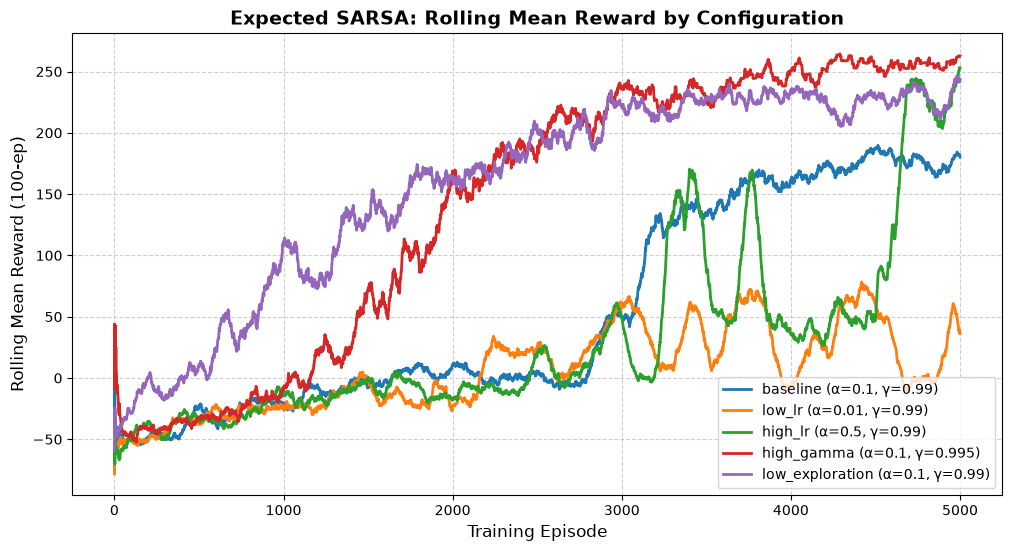

In [8]:
plt.figure(figsize=(12, 6))
plotted_runs = 0

for index, row in experiments_df.iterrows():
    run_name = row['run_name']
    data_file = f"run_{run_name}_data.csv"
    
    if os.path.exists(data_file):
        run_df = pd.read_csv(data_file)
        
        # Use a rolling window of 100 episodes to smooth out the noisy RL data
        rolling_window = 100
        run_df["rolling_reward"] = run_df["Reward"].rolling(window=rolling_window, min_periods=1).mean()
        
        plt.plot(
            run_df["Episode"],
            run_df["rolling_reward"],
            linewidth=2.0,
            label=f"{run_name} (α={row['alpha']}, γ={row['gamma']})"
        )
        plotted_runs += 1

if plotted_runs > 0:
    plt.title("Expected SARSA: Rolling Mean Reward by Configuration", fontsize=14, fontweight="bold")
    plt.xlabel("Training Episode", fontsize=12)
    plt.ylabel(f"Rolling Mean Reward ({rolling_window}-ep)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="lower right", fontsize=10)
    plt.savefig("comparative_learning_curves.png", dpi=300, bbox_inches="tight")
else:
    print("No data available to plot.")

### 6. Graph Analysis: Win/Loss Distribution
**What it proves: Agent Effectiveness**

This graph is critical evidence for the report because it translates thousands of episodes of abstract learning math (Q-values) into tangible reality. By categorizing the outcomes into concrete wins (2 apples) and losses (0 or 1 apple), it acts as the ultimate proof of which hyperparameter configuration is the most reliable at actually completing the objective.

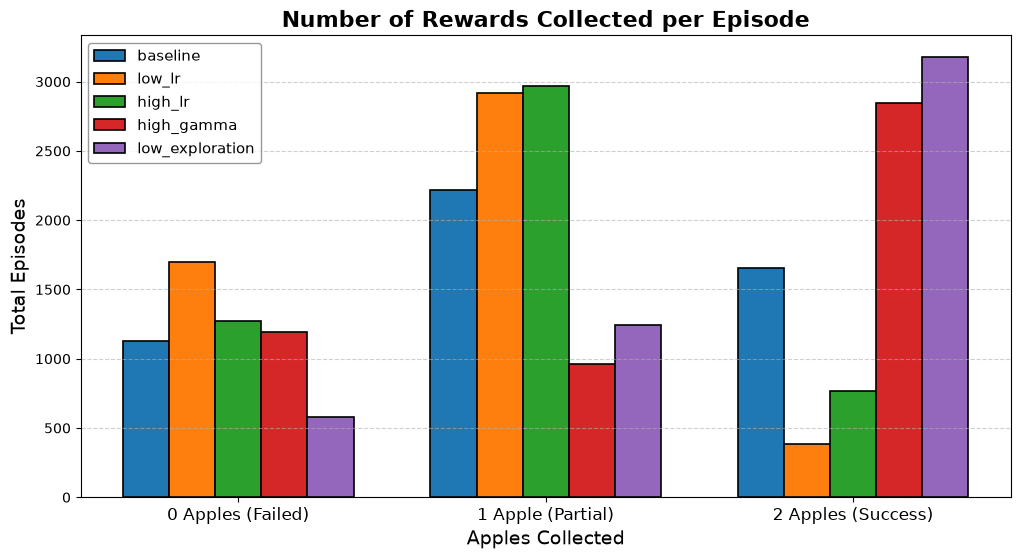

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

plt.figure(figsize=(12, 6))

# Lists to store the extracted data
run_names = []
apple_0_counts = []
apple_1_counts = []
apple_2_counts = []

# 1. Gather all the data first
for index, row in experiments_df.iterrows():
    run_name = row['run_name']
    data_file = f"run_{run_name}_data.csv"

    if os.path.exists(data_file):
        run_df = pd.read_csv(data_file)
        run_names.append(run_name)

        # Count the occurrences of 0, 1, and 2 apples
        counts = run_df['Apples_Collected'].value_counts()
        apple_0_counts.append(counts.get(0, 0))
        apple_1_counts.append(counts.get(1, 0))
        apple_2_counts.append(counts.get(2, 0))

# 2. Plot the grouped bar chart
if len(run_names) > 0:
    x = np.arange(3)  # The label locations for the 3 categories (0, 1, 2 apples)
    width = 0.15      # The width of the individual bars
    multiplier = 0

    for i, name in enumerate(run_names):
        offset = width * multiplier
        bar_data = [apple_0_counts[i], apple_1_counts[i], apple_2_counts[i]]

        # Plot this specific run's bars with a black edge for clarity
        plt.bar(x + offset, bar_data, width, label=name, edgecolor='black', linewidth=1.2)
        multiplier += 1

    plt.title("Number of Rewards Collected per Episode", fontsize=16, fontweight="bold")
    plt.xlabel("Apples Collected", fontsize=14)
    plt.ylabel("Total Episodes", fontsize=14)

    # Center the X-axis labels perfectly beneath the grouped bars
    plt.xticks(
        x + width * (len(run_names) - 1) / 2,
        ["0 Apples (Failed)", "1 Apple (Partial)", "2 Apples (Success)"],
        fontsize=12
    )

    plt.grid(axis='y', linestyle="--", alpha=0.6)
    plt.legend(loc="upper left", fontsize=11, edgecolor='grey')
    plt.savefig("comparative_apple_distribution.png", dpi=300, bbox_inches="tight")
else:
    print("No data available to plot.")

### 7. Graph Analysis: Distance Travelled (Macro Steps)
**What it proves: Agent Efficiency**

Winning is not enough if the agent takes 80 steps pacing back and forth out of hesitation. This graph serves as evidence of the agent's confidence. A stabilized, low step-count trendline proves that the agent didn't just get lucky; it definitively memorized the most optimal, direct route to the final apple without wasting time.

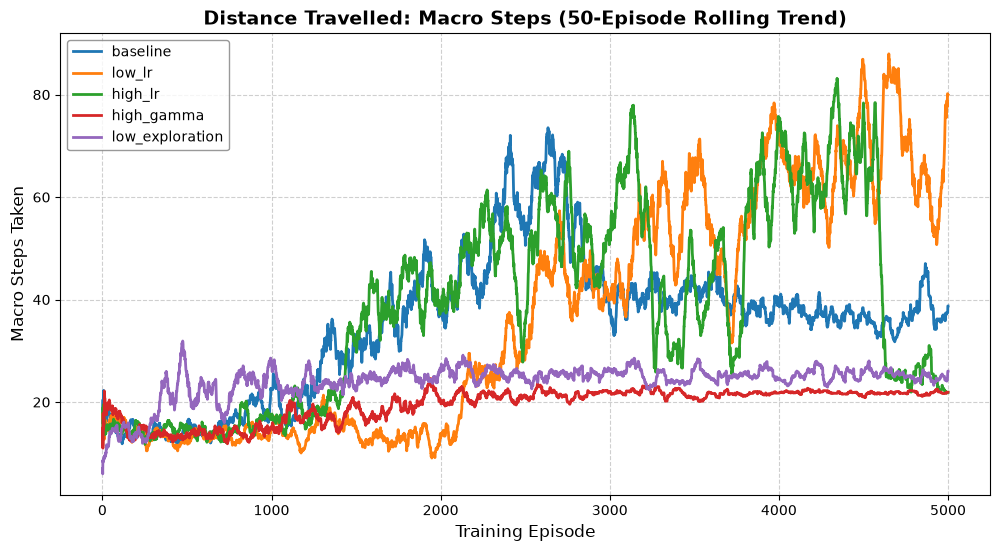

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import os

plt.figure(figsize=(12, 6))
plotted_runs = 0

for index, row in experiments_df.iterrows():
    run_name = row['run_name']
    data_file = f"run_{run_name}_data.csv"

    if os.path.exists(data_file):
        run_df = pd.read_csv(data_file)

        # Use a rolling window of 50 episodes as per your graph title
        rolling_window = 50
        run_df["rolling_steps"] = run_df["Macro_Steps"].rolling(window=rolling_window, min_periods=1).mean()

        plt.plot(
            run_df["Episode"],
            run_df["rolling_steps"],
            linewidth=2.0,
            label=run_name
        )
        plotted_runs += 1

if plotted_runs > 0:
    plt.title("Distance Travelled: Macro Steps (50-Episode Rolling Trend)", fontsize=14, fontweight="bold")
    plt.xlabel("Training Episode", fontsize=12)
    plt.ylabel("Macro Steps Taken", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="upper left", fontsize=10, edgecolor='grey')
    plt.savefig("comparative_macro_steps.png", dpi=300, bbox_inches="tight")
else:
    print("No data available to plot.")